<a id='1'></a><center> <h3 style="background-color:orange; color:white" ><br>Green Destinations: Employee Attrition & HR Analytics Assignment<br></h3></center>

# Introduction
This Jupyter notebook is part of your learning experience in Applied Data Analytics and Workforce Intelligence using Python. In this project, we address the strategic business brief from **Green Destinations**, a well-known travel agency where the HR Director has observed an escalating rate of employee turnover.

### Project Brief & Core Objectives:
1. **Determine the Baseline Attrition Rate**: Calculate the exact percentage of employees who have separated from Green Destinations.
2. **Evaluate Core Determinants**: Empirically investigate whether **Age**, **Years at the Company (Tenure)**, and **Income (Monthly Income)** significantly influence employee departure decisions.
3. **Multivariate Workplace Diagnostics**: Examine secondary organizational drivers including overtime commitments, department-level dynamics, job satisfaction ratings, and work-life balance scores.
4. **Statistical Hypothesis Testing**: Conduct formal parametric (t-tests) and non-parametric (chi-square tests) statistical evaluations to validate empirical significance.
5. **Predictive Modeling**: Train and evaluate machine learning classifiers (Logistic Regression, Random Forest) to identify key attrition drivers and risk scores.
6. **Executive Action Plan**: Provide the HR Director with data-driven retention and compensation recommendations.


In [1]:
# Task 1: Import Core Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn for predictive workforce modeling
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)

# Styling configuration
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
sns.set_theme(style='whitegrid', palette='Set2')

print("Libraries imported successfully!")


Libraries imported successfully!


---
## Task 2: Dataset Ingestion & Structural Inspection


In [2]:
# Task 2: Load the Green Destinations Dataset
df = pd.read_csv('greendestination.csv')
print(f"Dataset Dimensions: {df.shape[0]} employees × {df.shape[1]} attributes")
print("\nFirst 5 Records:")
df.head()


Dataset Dimensions: 1470 employees × 35 attributes

First 5 Records:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
# Task 2b: Data Types & Schema Overview
print("=== Schema Information ===")
df.info()


=== Schema Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 1

In [4]:
# Task 2c: Missing Values & Data Hygiene Audit
missing_counts = df.isnull().sum()
total_missing = missing_counts.sum()
print("Missing values per column:")
print(missing_counts[missing_counts > 0] if total_missing > 0 else "Zero missing values across all columns!")
print(f"\nDuplicate employee records: {df.duplicated().sum()}")


Missing values per column:
Zero missing values across all columns!

Duplicate employee records: 0


In [5]:
# Task 2d: Zero-Variance Constants & Identifier Check
# Identify columns with constant single values
constant_cols = [c for c in df.columns if df[c].nunique() <= 1]
print(f"Constant/Zero-variance columns: {constant_cols}")
for c in constant_cols:
    print(f"  - {c}: unique value = {df[c].unique()}")

print(f"EmployeeNumber is unique key: {df['EmployeeNumber'].nunique() == len(df)}")


Constant/Zero-variance columns: ['EmployeeCount', 'Over18', 'StandardHours']
  - EmployeeCount: unique value = [1]
  - Over18: unique value = ['Y']
  - StandardHours: unique value = [80]
EmployeeNumber is unique key: True


---
## Task 3: Core Objective 1 — Overall Attrition Rate Calculation

Determine the exact attrition rate (% of employees who have left Green Destinations).


=== Green Destinations Overall Attrition Summary ===
           Headcount  Percentage (%)
Attrition                           
No              1233           83.88
Yes              237           16.12

>>> OVERALL ATTRITION RATE: 16.12% (237 out of 1470 employees) <<<


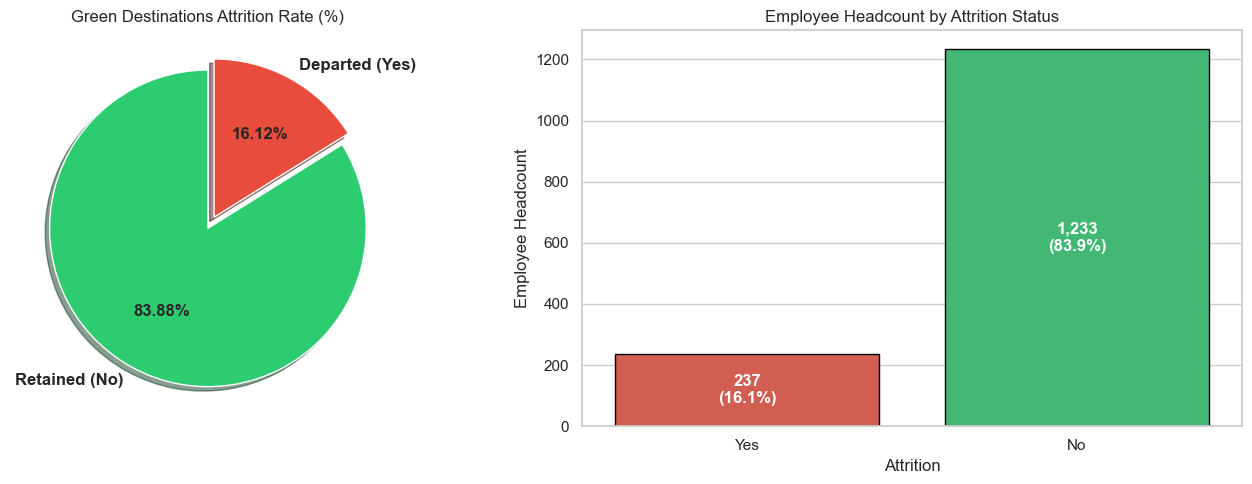

In [6]:
# Task 3: Calculate Attrition Frequency & Percentage
attrition_counts = df['Attrition'].value_counts()
attrition_pcts = df['Attrition'].value_counts(normalize=True) * 100

attrition_summary = pd.DataFrame({
    'Headcount': attrition_counts,
    'Percentage (%)': attrition_pcts.round(2)
})
print("=== Green Destinations Overall Attrition Summary ===")
print(attrition_summary)

attrition_rate = attrition_pcts['Yes']
print(f"\n>>> OVERALL ATTRITION RATE: {attrition_rate:.2f}% ({attrition_counts['Yes']} out of {len(df)} employees) <<<")

# Visualize Overall Attrition
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].pie(attrition_counts, labels=['Retained (No)', 'Departed (Yes)'], autopct='%1.2f%%',
            colors=['#2ecc71', '#e74c3c'], startangle=90, explode=(0, 0.08),
            shadow=True, textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[0].set_title('Green Destinations Attrition Rate (%)')

sns.countplot(data=df, x='Attrition', ax=axes[1], palette=['#e74c3c', '#2ecc71'], order=['Yes', 'No'], edgecolor='black')
axes[1].set_title('Employee Headcount by Attrition Status')
axes[1].set_ylabel('Employee Headcount')
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height()):,}\n({p.get_height()/len(df)*100:.1f}%)",
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()


---
## Task 4: Core Objective 2 — Age Dynamics vs. Attrition

Examine whether employee age plays a role in turnover at Green Destinations.


=== Age Metrics by Attrition Status ===
           count   mean  median   std  min  max
Attrition                                      
No          1233  37.56    36.0  8.89   18   60
Yes          237  33.61    32.0  9.69   18   58

Mean Age Difference: Employees who leave are on average 3.95 years younger.


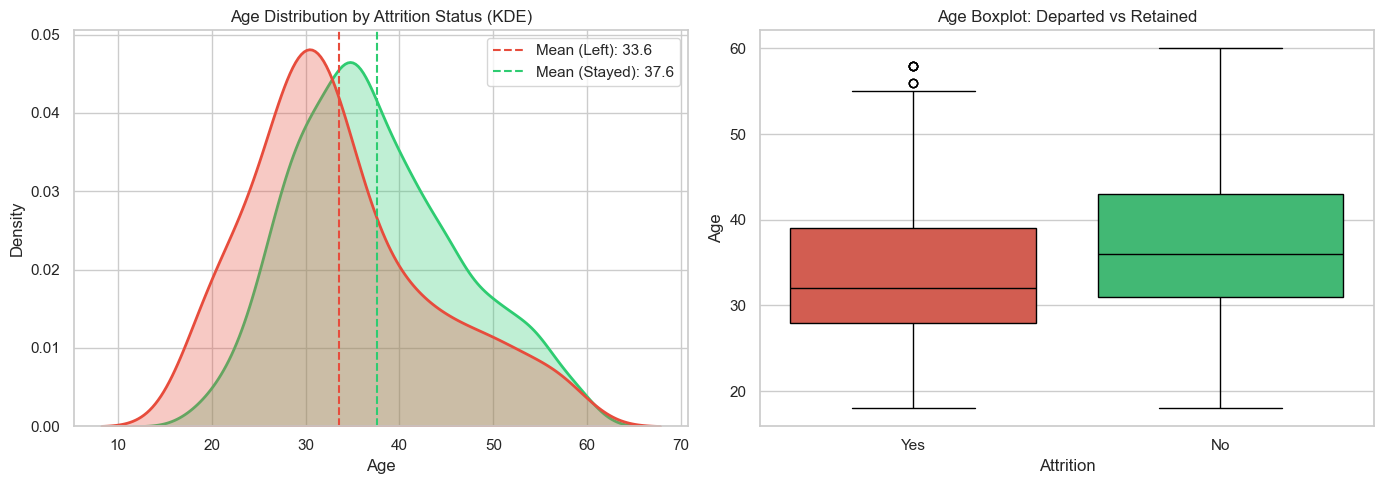

In [7]:
# Task 4a: Descriptive Metrics of Age by Attrition
age_stats = df.groupby('Attrition')['Age'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)
print("=== Age Metrics by Attrition Status ===")
print(age_stats)

diff_age_mean = age_stats.loc['No', 'mean'] - age_stats.loc['Yes', 'mean']
print(f"\nMean Age Difference: Employees who leave are on average {diff_age_mean:.2f} years younger.")

# Visualizations: Age Distribution (KDE) and Boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.kdeplot(data=df, x='Age', hue='Attrition', ax=axes[0], palette=['#e74c3c', '#2ecc71'],
            common_norm=False, fill=True, alpha=0.3, linewidth=2)
axes[0].axvline(df[df['Attrition']=='Yes']['Age'].mean(), color='#e74c3c', linestyle='--', label='Mean (Left): 33.6')
axes[0].axvline(df[df['Attrition']=='No']['Age'].mean(), color='#2ecc71', linestyle='--', label='Mean (Stayed): 37.6')
axes[0].set_title('Age Distribution by Attrition Status (KDE)')
axes[0].legend()

sns.boxplot(data=df, x='Attrition', y='Age', ax=axes[1], palette=['#e74c3c', '#2ecc71'], linecolor='black')
axes[1].set_title('Age Boxplot: Departed vs Retained')
plt.tight_layout()
plt.show()


=== Attrition Rate Across Age Cohorts ===
                      Total  Left  Attrition_Rate
Age_Group                                        
18-25 (Young)           123    44           35.77
26-35 (Early Career)    606   116           19.14
36-45 (Mid Career)      468    43            9.19
46-55 (Experienced)     226    26           11.50
56+ (Senior)             47     8           17.02


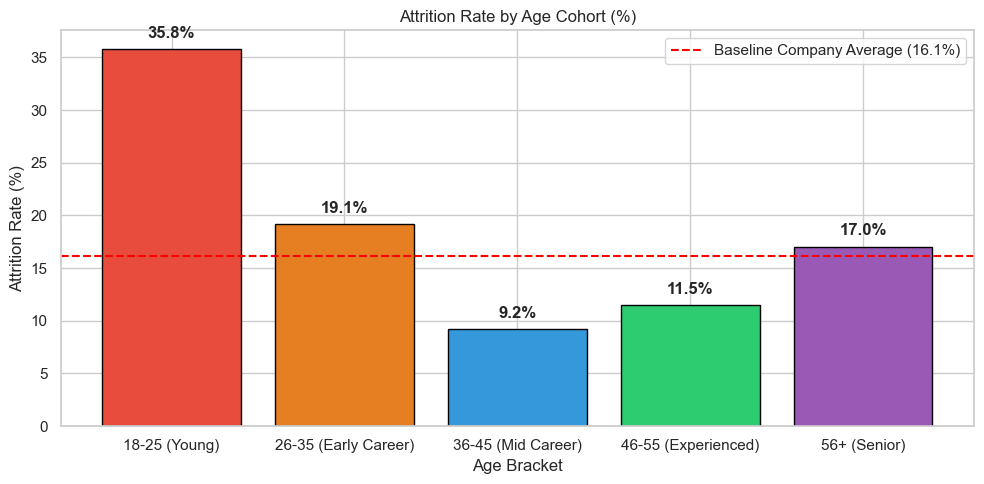

In [8]:
# Task 4b: Attrition Rate by Age Cohorts
df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 45, 55, 65],
    labels=['18-25 (Young)', '26-35 (Early Career)', '36-45 (Mid Career)', '46-55 (Experienced)', '56+ (Senior)']
)

age_cohort_summary = df.groupby('Age_Group', observed=True).agg(
    Total=('Attrition', 'count'),
    Left=('Attrition', lambda x: (x == 'Yes').sum()),
    Attrition_Rate=('Attrition', lambda x: (x == 'Yes').mean() * 100)
).round(2)
print("=== Attrition Rate Across Age Cohorts ===")
print(age_cohort_summary)

plt.figure(figsize=(10, 5))
bars = plt.bar(age_cohort_summary.index.astype(str), age_cohort_summary['Attrition_Rate'],
               color=['#e74c3c', '#e67e22', '#3498db', '#2ecc71', '#9b59b6'], edgecolor='black')
plt.title('Attrition Rate by Age Cohort (%)')
plt.xlabel('Age Bracket')
plt.ylabel('Attrition Rate (%)')
plt.axhline(attrition_rate, color='red', linestyle='--', label=f'Baseline Company Average ({attrition_rate:.1f}%)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.8, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()


---
## Task 5: Core Objective 3 — Years at the Company (Tenure) vs. Attrition

Assess the relationship between tenure at Green Destinations and voluntary separation.


=== Years At Company Metrics by Attrition ===
           count  mean  median   std  min  max
Attrition                                     
No          1233  7.37     6.0  6.10    0   37
Yes          237  5.13     3.0  5.95    0   40

Median Tenure Disparity: Retained staff have 3.0 years longer tenure (6 yrs vs 3 yrs).


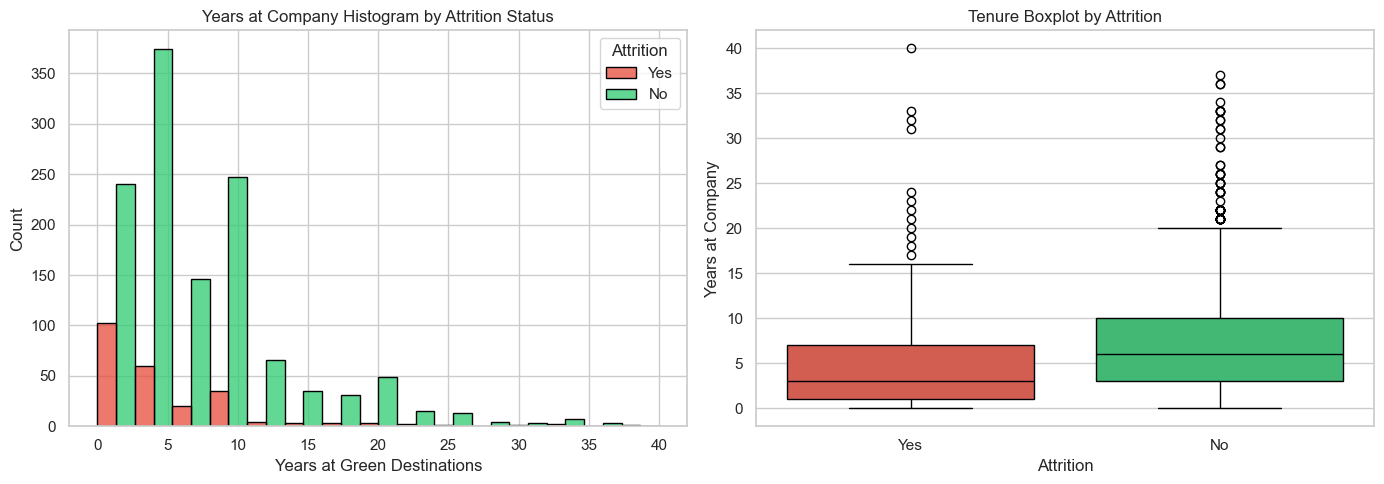

In [9]:
# Task 5a: Descriptive Metrics of Years at Company
tenure_stats = df.groupby('Attrition')['YearsAtCompany'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)
print("=== Years At Company Metrics by Attrition ===")
print(tenure_stats)

diff_tenure_med = tenure_stats.loc['No', 'median'] - tenure_stats.loc['Yes', 'median']
print(f"\nMedian Tenure Disparity: Retained staff have {diff_tenure_med:.1f} years longer tenure (6 yrs vs 3 yrs).")

# Visualizations: Tenure Distribution & Boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x='YearsAtCompany', hue='Attrition', ax=axes[0], multiple='dodge',
             bins=15, palette=['#e74c3c', '#2ecc71'], edgecolor='black')
axes[0].set_title('Years at Company Histogram by Attrition Status')
axes[0].set_xlabel('Years at Green Destinations')

sns.boxplot(data=df, x='Attrition', y='YearsAtCompany', ax=axes[1], palette=['#e74c3c', '#2ecc71'], linecolor='black')
axes[1].set_title('Tenure Boxplot by Attrition')
axes[1].set_ylabel('Years at Company')
plt.tight_layout()
plt.show()


=== Attrition Rate Across Tenure Brackets ===
                       Headcount  Left  Attrition_Rate
Tenure_Bracket                                        
0-1 Years (New Hires)        215    75           34.88
2-3 Years                    255    47           18.43
4-5 Years                    306    40           13.07
6-10 Years                   448    55           12.28
11-20 Years                  180    12            6.67
20+ Years                     66     8           12.12


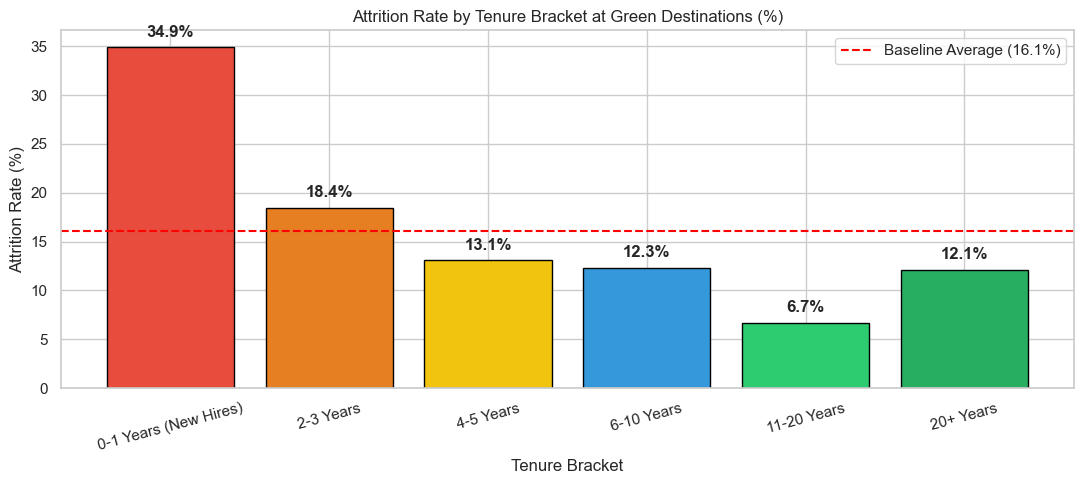

In [10]:
# Task 5b: Attrition Rate by Tenure Brackets
df['Tenure_Bracket'] = pd.cut(
    df['YearsAtCompany'],
    bins=[-1, 1, 3, 5, 10, 20, 50],
    labels=['0-1 Years (New Hires)', '2-3 Years', '4-5 Years', '6-10 Years', '11-20 Years', '20+ Years']
)

tenure_summary = df.groupby('Tenure_Bracket', observed=True).agg(
    Headcount=('Attrition', 'count'),
    Left=('Attrition', lambda x: (x == 'Yes').sum()),
    Attrition_Rate=('Attrition', lambda x: (x == 'Yes').mean() * 100)
).round(2)
print("=== Attrition Rate Across Tenure Brackets ===")
print(tenure_summary)

plt.figure(figsize=(11, 5))
bars = plt.bar(tenure_summary.index.astype(str), tenure_summary['Attrition_Rate'],
               color=['#e74c3c', '#e67e22', '#f1c40f', '#3498db', '#2ecc71', '#27ae60'], edgecolor='black')
plt.title('Attrition Rate by Tenure Bracket at Green Destinations (%)')
plt.xlabel('Tenure Bracket')
plt.ylabel('Attrition Rate (%)')
plt.axhline(attrition_rate, color='red', linestyle='--', label=f'Baseline Average ({attrition_rate:.1f}%)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.8, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()


---
## Task 6: Core Objective 4 — Compensation (Monthly Income) vs. Attrition

Analyze whether salary and income disparity trigger employee resignations.


=== Monthly Income Metrics by Attrition ===
           count     mean  median      std   min    max
Attrition                                              
No          1233  6832.74  5204.0  4818.21  1051  19999
Yes          237  4787.09  3202.0  3640.21  1009  19859

Income Gap: Non-attrited staff earn on average $2,045.65 more per month.
Median Income Gap: $2,002.00 per month (62.5% higher).


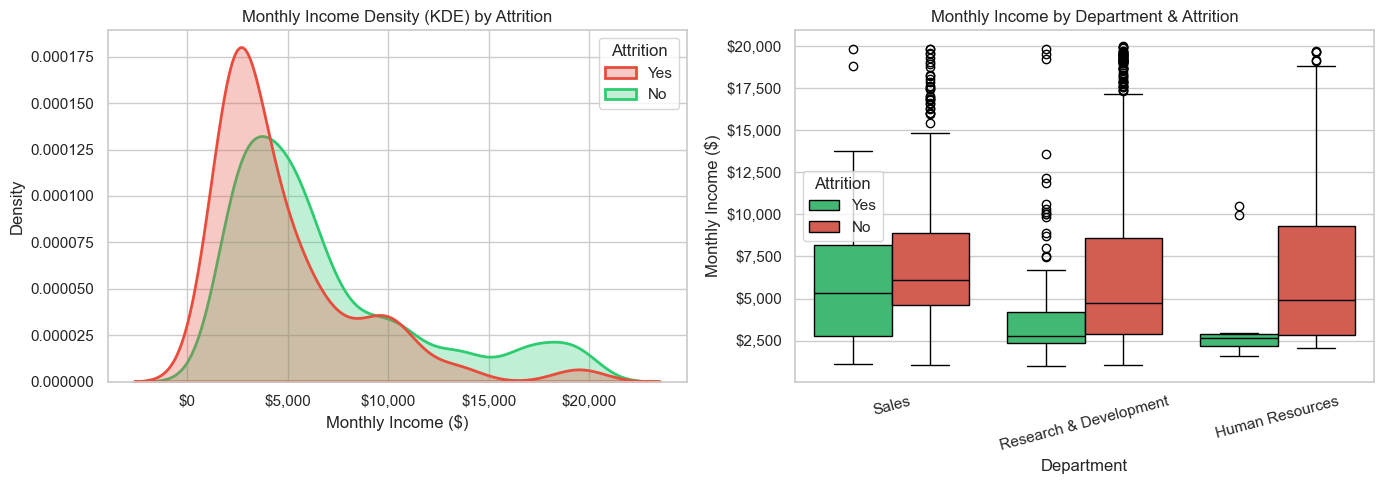

In [11]:
# Task 6a: Income Metrics by Attrition Status
income_stats = df.groupby('Attrition')['MonthlyIncome'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)
print("=== Monthly Income Metrics by Attrition ===")
print(income_stats)

income_mean_gap = income_stats.loc['No', 'mean'] - income_stats.loc['Yes', 'mean']
income_med_gap = income_stats.loc['No', 'median'] - income_stats.loc['Yes', 'median']
print(f"\nIncome Gap: Non-attrited staff earn on average ${income_mean_gap:,.2f} more per month.")
print(f"Median Income Gap: ${income_med_gap:,.2f} per month ({income_med_gap/income_stats.loc['Yes','median']*100:.1f}% higher).")

# Visualizations: Income KDE & Boxplot by Department
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.kdeplot(data=df, x='MonthlyIncome', hue='Attrition', ax=axes[0], palette=['#e74c3c', '#2ecc71'],
            common_norm=False, fill=True, alpha=0.3, linewidth=2)
axes[0].set_title('Monthly Income Density (KDE) by Attrition')
axes[0].set_xlabel('Monthly Income ($)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

sns.boxplot(data=df, x='Department', y='MonthlyIncome', hue='Attrition', ax=axes[1],
            palette=['#2ecc71', '#e74c3c'], linecolor='black')
axes[1].set_title('Monthly Income by Department & Attrition')
axes[1].set_ylabel('Monthly Income ($)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()


=== Attrition Rate Across Monthly Income Brackets ===
                   Headcount  Left  Attrition_Rate
Income_Bracket                                    
< $3K (Entry)            395   113           28.61
$3K-$5K (Junior)         354    50           14.12
$5K-$8K (Mid)            340    34           10.00
$8K-$12K (Senior)        186    29           15.59
$12K+ (Executive)        195    11            5.64


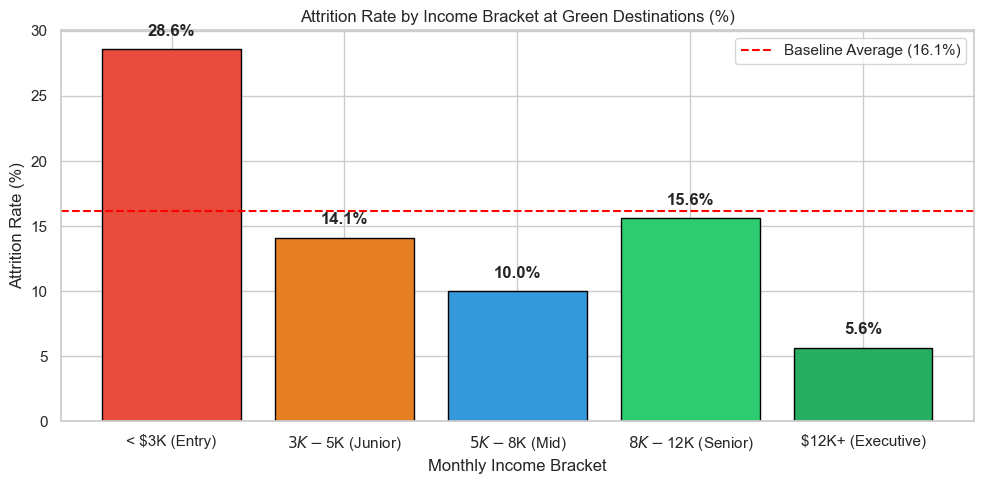

In [12]:
# Task 6b: Attrition Rate by Income Brackets
df['Income_Bracket'] = pd.cut(
    df['MonthlyIncome'],
    bins=[1000, 3000, 5000, 8000, 12000, 25000],
    labels=['< $3K (Entry)', '$3K-$5K (Junior)', '$5K-$8K (Mid)', '$8K-$12K (Senior)', '$12K+ (Executive)']
)

income_summary = df.groupby('Income_Bracket', observed=True).agg(
    Headcount=('Attrition', 'count'),
    Left=('Attrition', lambda x: (x == 'Yes').sum()),
    Attrition_Rate=('Attrition', lambda x: (x == 'Yes').mean() * 100)
).round(2)
print("=== Attrition Rate Across Monthly Income Brackets ===")
print(income_summary)

plt.figure(figsize=(10, 5))
bars = plt.bar(income_summary.index.astype(str), income_summary['Attrition_Rate'],
               color=['#e74c3c', '#e67e22', '#3498db', '#2ecc71', '#27ae60'], edgecolor='black')
plt.title('Attrition Rate by Income Bracket at Green Destinations (%)')
plt.xlabel('Monthly Income Bracket')
plt.ylabel('Attrition Rate (%)')
plt.axhline(attrition_rate, color='red', linestyle='--', label=f'Baseline Average ({attrition_rate:.1f}%)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.8, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()


---
## Task 7: Operational & Workplace Environmental Factors

Investigate OverTime, Departmental roles, Work-Life Balance, and Job Satisfaction.


=== OverTime vs Attrition Summary ===
Counts:
Attrition   No  Yes
OverTime           
No         944  110
Yes        289  127

Percentages (%):
Attrition     No    Yes
OverTime               
No         89.56  10.44
Yes        69.47  30.53

OverTime Risk Factor: Employees working OverTime exhibit 30.5% attrition vs 10.4% without OverTime.
OverTime increases attrition likelihood by 2.93x!


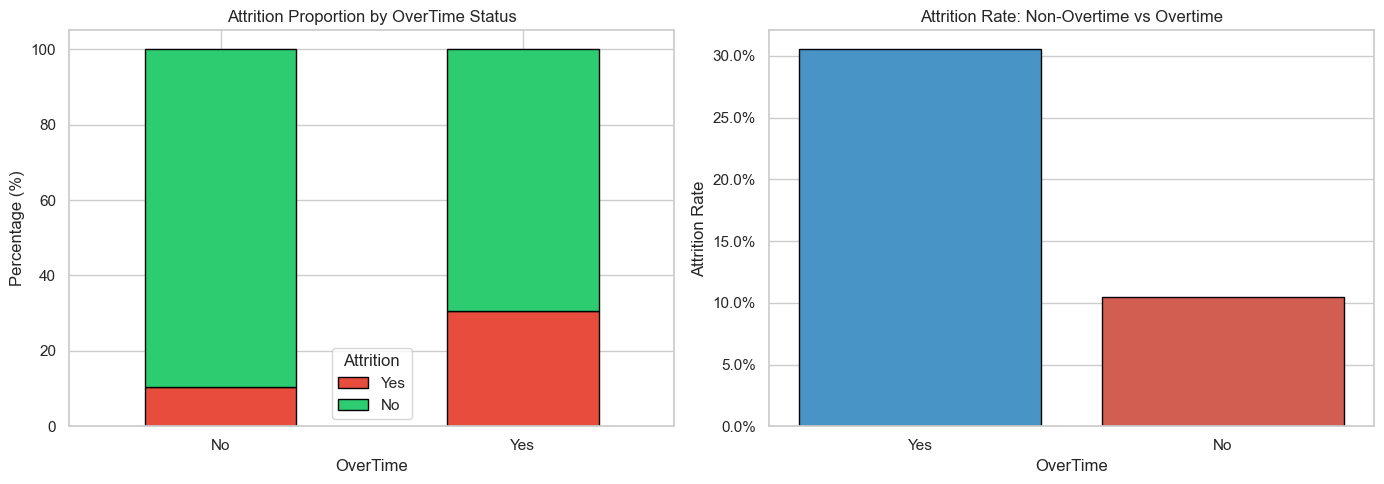

In [13]:
# Task 7a: OverTime Impact Analysis
overtime_summary = pd.crosstab(df['OverTime'], df['Attrition'], normalize='index') * 100
overtime_counts = pd.crosstab(df['OverTime'], df['Attrition'])
print("=== OverTime vs Attrition Summary ===")
print("Counts:")
print(overtime_counts)
print("\nPercentages (%):")
print(overtime_summary.round(2))

ot_yes_rate = overtime_summary.loc['Yes', 'Yes']
ot_no_rate = overtime_summary.loc['No', 'Yes']
print(f"\nOverTime Risk Factor: Employees working OverTime exhibit {ot_yes_rate:.1f}% attrition vs {ot_no_rate:.1f}% without OverTime.")
print(f"OverTime increases attrition likelihood by {ot_yes_rate / ot_no_rate:.2f}x!")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
overtime_summary[['Yes', 'No']].plot(kind='bar', stacked=True, ax=axes[0], color=['#e74c3c', '#2ecc71'], edgecolor='black')
axes[0].set_title('Attrition Proportion by OverTime Status')
axes[0].set_ylabel('Percentage (%)')
axes[0].tick_params(axis='x', rotation=0)

sns.barplot(data=df, x='OverTime', y=(df['Attrition']=='Yes').astype(int), ax=axes[1],
            palette=['#3498db', '#e74c3c'], errorbar=None, edgecolor='black')
axes[1].set_title('Attrition Rate: Non-Overtime vs Overtime')
axes[1].set_ylabel('Attrition Rate')
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()


=== Departmental Attrition Breakdown ===
                        Total  Left  Attrition_Rate
Department                                         
Sales                     446    92           20.63
Human Resources            63    12           19.05
Research & Development    961   133           13.84

=== Job Role Attrition Breakdown ===
                           Total  Left  Attrition_Rate  Median_Income
JobRole                                                              
Sales Representative          83    33           39.76         2579.0
Laboratory Technician        259    62           23.94         2886.0
Human Resources               52    12           23.08         3093.0
Sales Executive              326    57           17.48         6231.0
Research Scientist           292    47           16.10         2887.5
Manufacturing Director       145    10            6.90         6447.0
Healthcare Representative    131     9            6.87         6811.0
Manager                      10

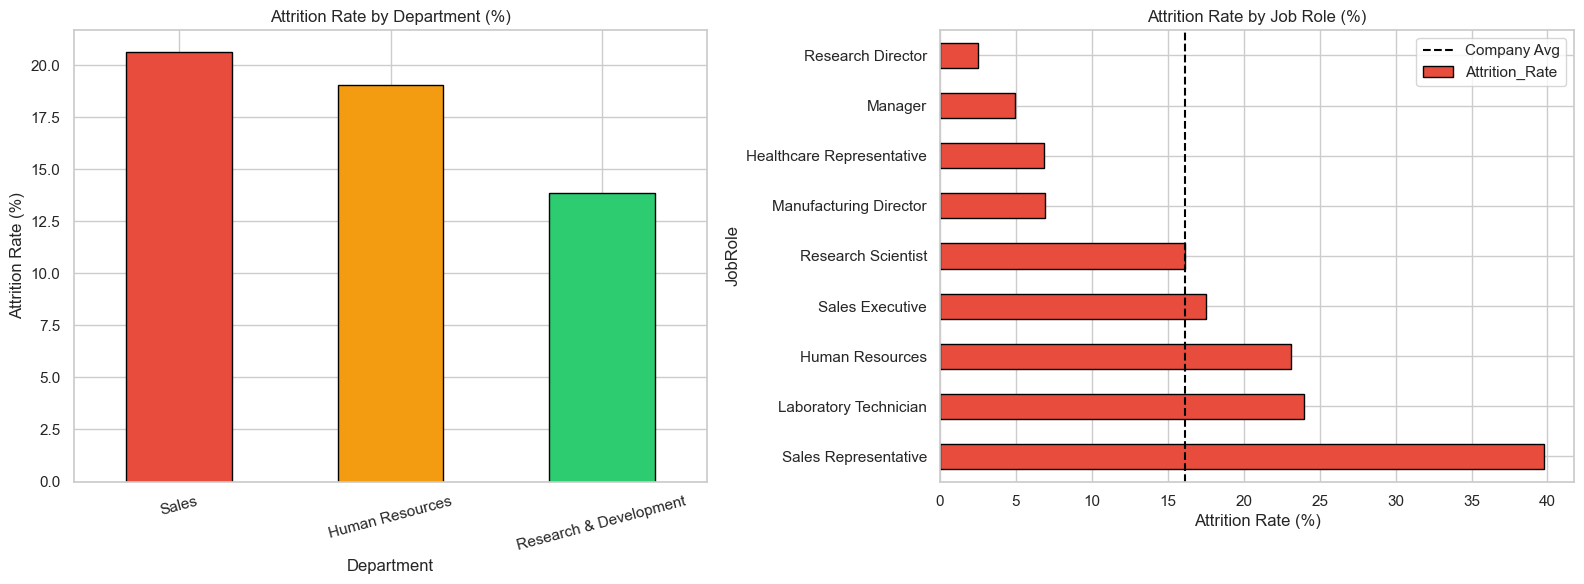

In [14]:
# Task 7b: Department & JobRole Breakdown
dept_summary = df.groupby('Department').agg(
    Total=('Attrition', 'count'),
    Left=('Attrition', lambda x: (x == 'Yes').sum()),
    Attrition_Rate=('Attrition', lambda x: (x == 'Yes').mean() * 100)
).round(2).sort_values('Attrition_Rate', ascending=False)
print("=== Departmental Attrition Breakdown ===")
print(dept_summary)

role_summary = df.groupby('JobRole').agg(
    Total=('Attrition', 'count'),
    Left=('Attrition', lambda x: (x == 'Yes').sum()),
    Attrition_Rate=('Attrition', lambda x: (x == 'Yes').mean() * 100),
    Median_Income=('MonthlyIncome', 'median')
).round(2).sort_values('Attrition_Rate', ascending=False)
print("\n=== Job Role Attrition Breakdown ===")
print(role_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
dept_summary['Attrition_Rate'].plot(kind='bar', ax=axes[0], color=['#e74c3c', '#f39c12', '#2ecc71'], edgecolor='black')
axes[0].set_title('Attrition Rate by Department (%)')
axes[0].set_ylabel('Attrition Rate (%)')
axes[0].tick_params(axis='x', rotation=15)

role_summary['Attrition_Rate'].plot(kind='barh', ax=axes[1], color='#e74c3c', edgecolor='black')
axes[1].set_title('Attrition Rate by Job Role (%)')
axes[1].set_xlabel('Attrition Rate (%)')
axes[1].axvline(attrition_rate, color='black', linestyle='--', label='Company Avg')
axes[1].legend()
plt.tight_layout()
plt.show()


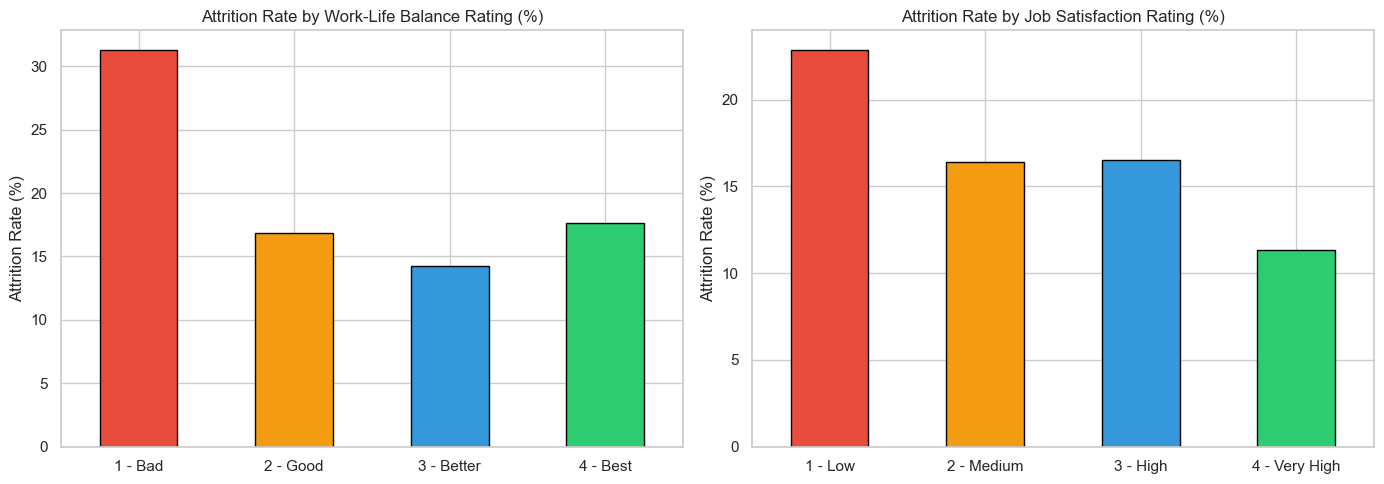

In [15]:
# Task 7c: Work-Life Balance & Job Satisfaction
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Work Life Balance (1=Bad, 2=Good, 3=Better, 4=Best)
wlb_surv = df.groupby('WorkLifeBalance')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
wlb_surv.index = ['1 - Bad', '2 - Good', '3 - Better', '4 - Best']
wlb_surv.plot(kind='bar', ax=axes[0], color=['#e74c3c', '#f39c12', '#3498db', '#2ecc71'], edgecolor='black')
axes[0].set_title('Attrition Rate by Work-Life Balance Rating (%)')
axes[0].set_ylabel('Attrition Rate (%)')
axes[0].tick_params(axis='x', rotation=0)

# Job Satisfaction (1=Low, 2=Medium, 3=High, 4=Very High)
js_surv = df.groupby('JobSatisfaction')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
js_surv.index = ['1 - Low', '2 - Medium', '3 - High', '4 - Very High']
js_surv.plot(kind='bar', ax=axes[1], color=['#e74c3c', '#f39c12', '#3498db', '#2ecc71'], edgecolor='black')
axes[1].set_title('Attrition Rate by Job Satisfaction Rating (%)')
axes[1].set_ylabel('Attrition Rate (%)')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


---
## Task 8: Formal Inferential Hypothesis Testing

Conduct formal statistical hypothesis tests to evaluate whether differences in Age, Tenure, Income, and OverTime are statistically significant.

### Tests Conducted:
1. **Welch's Two-Sample t-test**:
   - $H_0$: The mean of Age / Tenure / Income is identical between employees who left and stayed.
   - $H_1$: The means differ significantly.
2. **Chi-Square Test of Independence**:
   - $H_0$: Attrition is independent of OverTime / Department / JobRole.
   - $H_1$: Attrition is dependent on the categorical workplace factor.


In [16]:
# Task 8a: Welch's Two-Sample t-tests
attr_yes = df[df['Attrition'] == 'Yes']
attr_no = df[df['Attrition'] == 'No']

tests = [
    ('Age', attr_yes['Age'], attr_no['Age']),
    ('YearsAtCompany', attr_yes['YearsAtCompany'], attr_no['YearsAtCompany']),
    ('MonthlyIncome', attr_yes['MonthlyIncome'], attr_no['MonthlyIncome']),
    ('TotalWorkingYears', attr_yes['TotalWorkingYears'], attr_no['TotalWorkingYears'])
]

ttest_results = []
for var_name, sample1, sample2 in tests:
    t_stat, p_val = stats.ttest_ind(sample1, sample2, equal_var=False)
    ttest_results.append({
        'Variable': var_name,
        'Mean (Left)': round(sample1.mean(), 2),
        'Mean (Stayed)': round(sample2.mean(), 2),
        'Difference': round(sample1.mean() - sample2.mean(), 2),
        't-Statistic': round(t_stat, 4),
        'P-Value': p_val,
        'Statistically Significant?': 'YES (p < 0.001)' if p_val < 0.001 else ('YES (p < 0.05)' if p_val < 0.05 else 'NO')
    })

ttest_df = pd.DataFrame(ttest_results)
print("=== Two-Sample Welch's t-Test Results ===")
print(ttest_df.to_string(index=False))


=== Two-Sample Welch's t-Test Results ===
         Variable  Mean (Left)  Mean (Stayed)  Difference  t-Statistic      P-Value Statistically Significant?
              Age        33.61          37.56       -3.95      -5.8280 1.379760e-08            YES (p < 0.001)
   YearsAtCompany         5.13           7.37       -2.24      -5.2826 2.285905e-07            YES (p < 0.001)
    MonthlyIncome      4787.09        6832.74    -2045.65      -7.4826 4.433589e-13            YES (p < 0.001)
TotalWorkingYears         8.24          11.86       -3.62      -7.0192 1.159817e-11            YES (p < 0.001)


In [17]:
# Task 8b: Chi-Square Tests of Independence
cat_factors = ['OverTime', 'Department', 'JobRole', 'BusinessTravel', 'MaritalStatus']
chi2_results = []

for factor in cat_factors:
    contingency_table = pd.crosstab(df[factor], df['Attrition'])
    chi2_val, p_val, dof, _ = stats.chi2_contingency(contingency_table)
    chi2_results.append({
        'Factor': factor,
        'Chi2-Statistic': round(chi2_val, 4),
        'Degrees of Freedom': dof,
        'P-Value': p_val,
        'Statistically Significant?': 'YES (p < 0.001)' if p_val < 0.001 else ('YES (p < 0.05)' if p_val < 0.05 else 'NO')
    })

chi2_df = pd.DataFrame(chi2_results)
print("=== Chi-Square Test of Independence Results ===")
print(chi2_df.to_string(index=False))


=== Chi-Square Test of Independence Results ===
        Factor  Chi2-Statistic  Degrees of Freedom      P-Value Statistically Significant?
      OverTime         87.5643                   1 8.158424e-21            YES (p < 0.001)
    Department         10.7960                   2 4.525607e-03             YES (p < 0.05)
       JobRole         86.1903                   8 2.752482e-15            YES (p < 0.001)
BusinessTravel         24.1824                   2 5.608614e-06            YES (p < 0.001)
 MaritalStatus         46.1637                   2 9.455511e-11            YES (p < 0.001)


---
## Task 9: Correlation Matrix & Linear Attrition Associations


=== Correlations with Attrition ===
TotalWorkingYears          -0.1711
JobLevel                   -0.1691
YearsInCurrentRole         -0.1605
MonthlyIncome              -0.1598
Age                        -0.1592
YearsWithCurrManager       -0.1562
StockOptionLevel           -0.1371
YearsAtCompany             -0.1344
JobInvolvement             -0.1300
JobSatisfaction            -0.1035
EnvironmentSatisfaction    -0.1034
WorkLifeBalance            -0.0639
TrainingTimesLastYear      -0.0595
DailyRate                  -0.0567
RelationshipSatisfaction   -0.0459
YearsSinceLastPromotion    -0.0330
Education                  -0.0314
PercentSalaryHike          -0.0135
EmployeeNumber             -0.0106
HourlyRate                 -0.0068
PerformanceRating           0.0029
MonthlyRate                 0.0152
NumCompaniesWorked          0.0435
DistanceFromHome            0.0779
Target_Attrition            1.0000
EmployeeCount                  NaN
StandardHours                  NaN
Name: Target_Attrit

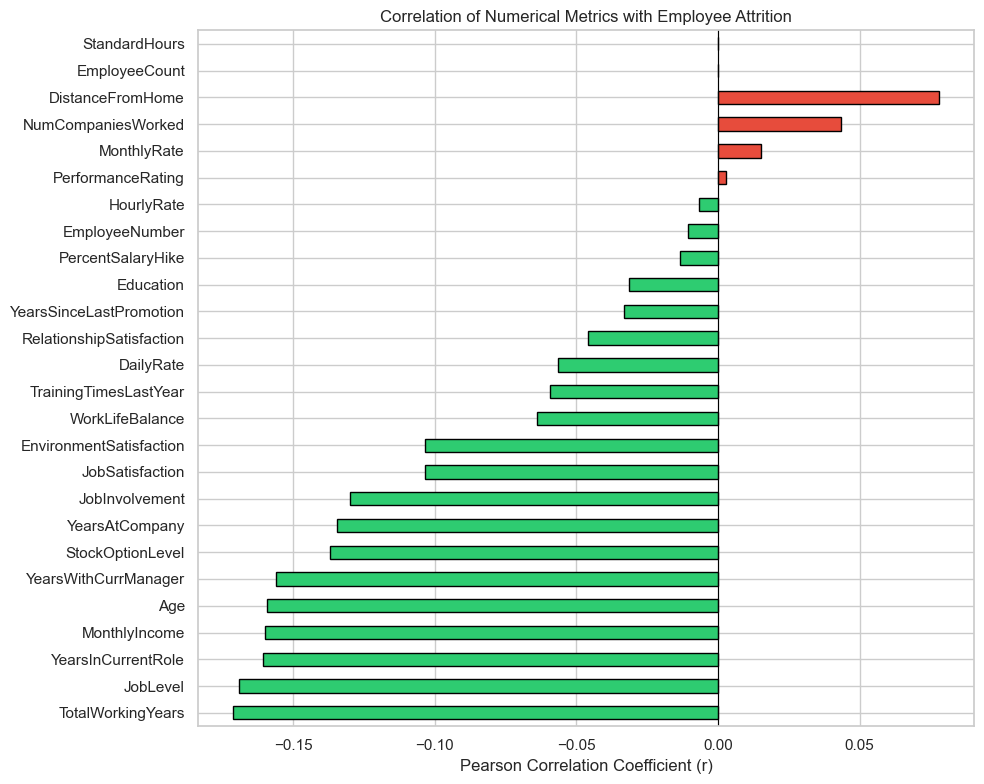

In [18]:
# Task 9: Correlation Analysis with Binary Target
df['Target_Attrition'] = (df['Attrition'] == 'Yes').astype(int)

# Numerical columns
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr_with_attrition = df[num_cols].corr()['Target_Attrition'].sort_values()

print("=== Correlations with Attrition ===")
print(corr_with_attrition.round(4))

plt.figure(figsize=(10, 8))
corr_with_attrition.drop('Target_Attrition').plot(kind='barh',
    color=['#2ecc71' if x < 0 else '#e74c3c' for x in corr_with_attrition.drop('Target_Attrition')],
    edgecolor='black')
plt.title('Correlation of Numerical Metrics with Employee Attrition')
plt.xlabel('Pearson Correlation Coefficient (r)')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()


---
## Task 10: Predictive Modeling & Feature Importance

Build classification models to predict employee attrition risk and quantify feature importance.


In [19]:
# Task 10a: Feature Engineering & Preprocessing
# Drop zero-variance columns and unique ID
clean_df = df.drop(columns=['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber',
                            'Age_Group', 'Tenure_Bracket', 'Income_Bracket', 'Target_Attrition'])

# Encode target
y = (clean_df['Attrition'] == 'Yes').astype(int)
X_raw = clean_df.drop(columns=['Attrition'])

# One-hot encode remaining categorical variables
X = pd.get_dummies(X_raw, drop_first=True, dtype=int)
print(f"Engineered Feature Matrix: {X.shape[0]} rows × {X.shape[1]} features")

# Stratified 80/20 Train-Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training set: {X_train.shape[0]} samples | Testing set: {X_test.shape[0]} samples")


Engineered Feature Matrix: 1470 rows × 44 features
Training set: 1176 samples | Testing set: 294 samples


In [20]:
# Task 10b: Train & Evaluate Classifiers
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=6, class_weight='balanced', random_state=42)
}

benchmarks = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    cv_acc = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc').mean()
    
    benchmarks.append({
        'Model': name,
        'CV ROC-AUC': round(cv_acc, 4),
        'Test Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(auc, 4)
    })
    trained_models[name] = model

print("=== Predictive Model Benchmarks ===")
print(pd.DataFrame(benchmarks).set_index('Model').to_string())


=== Predictive Model Benchmarks ===
                     CV ROC-AUC  Test Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                                               
Logistic Regression      0.7834         0.7619     0.3580  0.6170    0.4531   0.7715
Random Forest            0.7722         0.8435     0.5135  0.4043    0.4524   0.7787


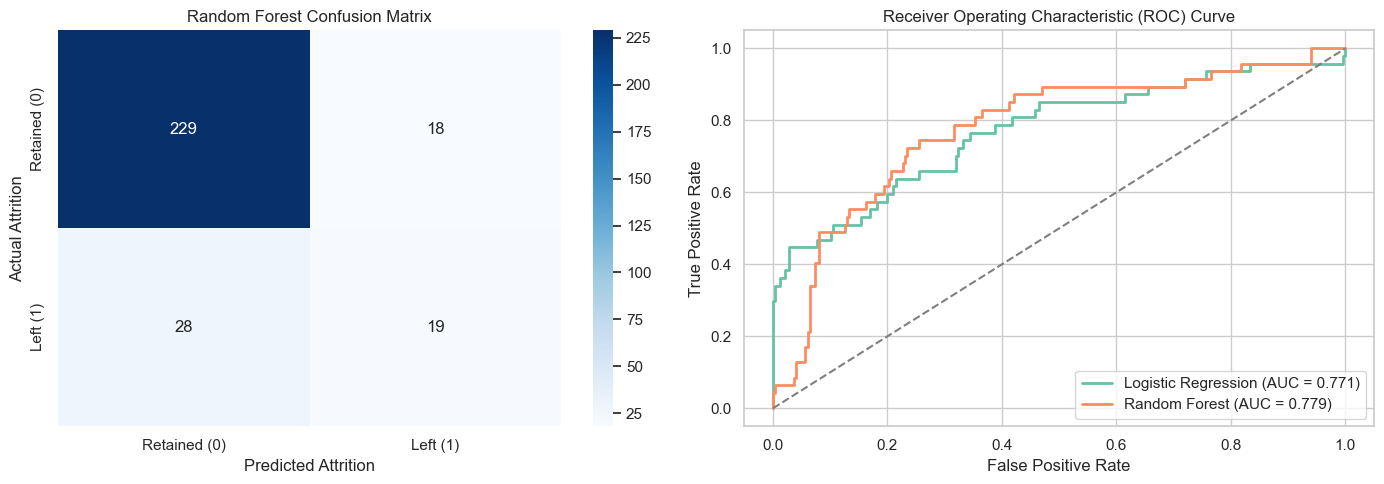


Classification Report (Random Forest):
              precision    recall  f1-score   support

    Retained       0.89      0.93      0.91       247
        Left       0.51      0.40      0.45        47

    accuracy                           0.84       294
   macro avg       0.70      0.67      0.68       294
weighted avg       0.83      0.84      0.84       294



In [21]:
# Task 10c: Confusion Matrix & ROC Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix for Random Forest
rf_mod = trained_models['Random Forest']
y_pred_rf = rf_mod.predict(X_test)
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Retained (0)', 'Left (1)'],
            yticklabels=['Retained (0)', 'Left (1)'])
axes[0].set_title('Random Forest Confusion Matrix')
axes[0].set_xlabel('Predicted Attrition')
axes[0].set_ylabel('Actual Attrition')

# ROC Curves
for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_v = roc_auc_score(y_test, y_prob)
    axes[1].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_v:.3f})")

axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

print("\nClassification Report (Random Forest):")
print(classification_report(y_test, y_pred_rf, target_names=['Retained', 'Left']))


=== Top 15 Drivers of Employee Attrition ===
MonthlyIncome              0.0819
Age                        0.0730
YearsAtCompany             0.0640
OverTime_Yes               0.0633
YearsWithCurrManager       0.0579
TotalWorkingYears          0.0570
StockOptionLevel           0.0446
DailyRate                  0.0436
NumCompaniesWorked         0.0380
MonthlyRate                0.0369
YearsInCurrentRole         0.0350
DistanceFromHome           0.0341
JobLevel                   0.0339
HourlyRate                 0.0332
EnvironmentSatisfaction    0.0261
dtype: float64


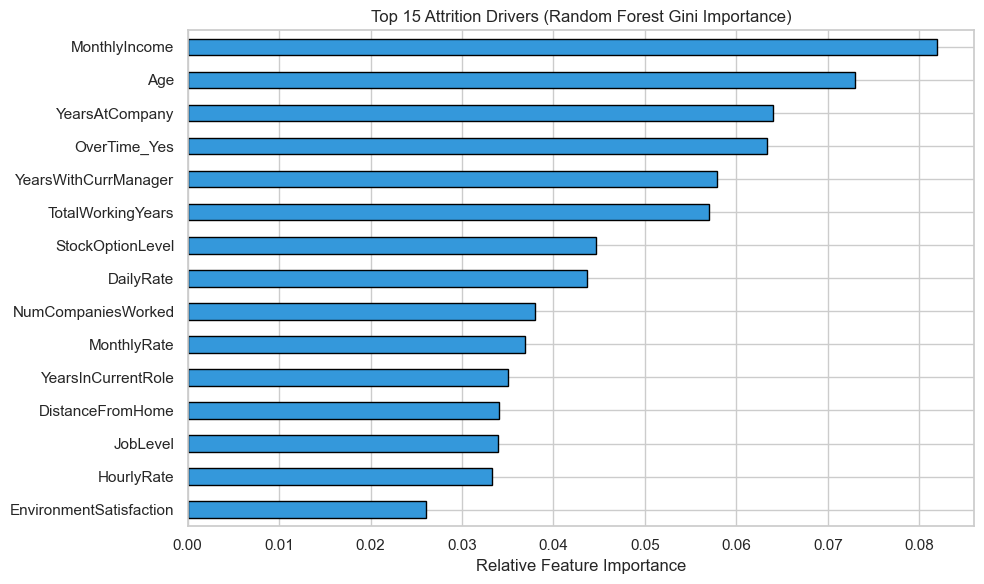

In [22]:
# Task 10d: Top Feature Importances (Random Forest)
feat_importances = pd.Series(rf_mod.feature_importances_, index=X.columns).sort_values(ascending=False)
top15_features = feat_importances.head(15)

print("=== Top 15 Drivers of Employee Attrition ===")
print(top15_features.round(4))

plt.figure(figsize=(10, 6))
top15_features.sort_values().plot(kind='barh', color='#3498db', edgecolor='black')
plt.title('Top 15 Attrition Drivers (Random Forest Gini Importance)')
plt.xlabel('Relative Feature Importance')
plt.tight_layout()
plt.show()


---
## Task 11: Executive HR Intelligence Dashboard

Consolidate findings into a multi-panel visual dashboard directly addressing the HR Director's brief.


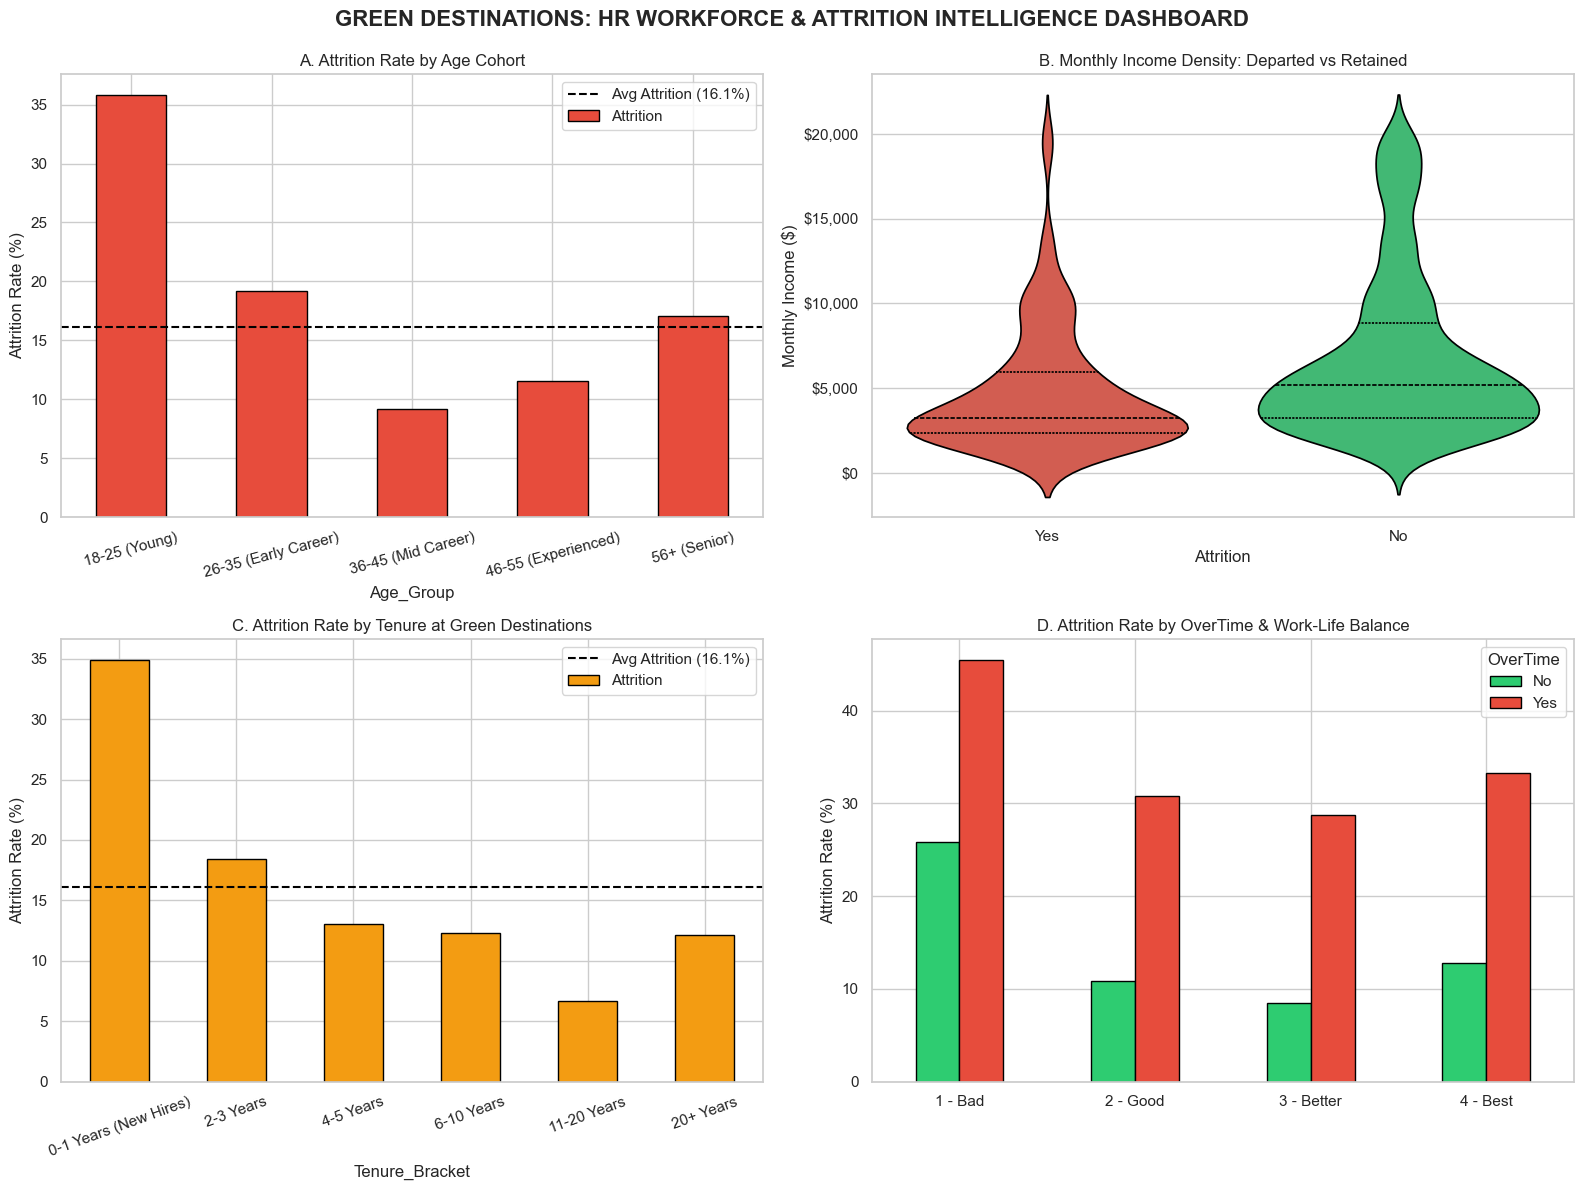

In [23]:
# Task 11: 4-Panel Executive Dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel 1: Attrition Rate & Age Gradient
age_band_plot = df.groupby('Age_Group', observed=True)['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
age_band_plot.plot(kind='bar', ax=axes[0, 0], color='#e74c3c', edgecolor='black')
axes[0, 0].axhline(attrition_rate, color='black', linestyle='--', label=f'Avg Attrition ({attrition_rate:.1f}%)')
axes[0, 0].set_title('A. Attrition Rate by Age Cohort')
axes[0, 0].set_ylabel('Attrition Rate (%)')
axes[0, 0].tick_params(axis='x', rotation=15)
axes[0, 0].legend()

# Panel 2: Monthly Income Distribution (Violin Plot)
sns.violinplot(data=df, x='Attrition', y='MonthlyIncome', ax=axes[0, 1], palette=['#e74c3c', '#2ecc71'], inner='quartile', linecolor='black')
axes[0, 1].set_title('B. Monthly Income Density: Departed vs Retained')
axes[0, 1].set_ylabel('Monthly Income ($)')
axes[0, 1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

# Panel 3: Tenure Risk Curve (Years at Company)
tenure_plot = df.groupby('Tenure_Bracket', observed=True)['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
tenure_plot.plot(kind='bar', ax=axes[1, 0], color='#f39c12', edgecolor='black')
axes[1, 0].axhline(attrition_rate, color='black', linestyle='--', label=f'Avg Attrition ({attrition_rate:.1f}%)')
axes[1, 0].set_title('C. Attrition Rate by Tenure at Green Destinations')
axes[1, 0].set_ylabel('Attrition Rate (%)')
axes[1, 0].tick_params(axis='x', rotation=20)
axes[1, 0].legend()

# Panel 4: OverTime & Work-Life Balance Intersect
ot_wlb = df.pivot_table(values='Attrition', index='WorkLifeBalance', columns='OverTime',
                        aggfunc=lambda x: (x == 'Yes').mean() * 100)
ot_wlb.index = ['1 - Bad', '2 - Good', '3 - Better', '4 - Best']
ot_wlb.plot(kind='bar', ax=axes[1, 1], color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[1, 1].set_title('D. Attrition Rate by OverTime & Work-Life Balance')
axes[1, 1].set_ylabel('Attrition Rate (%)')
axes[1, 1].tick_params(axis='x', rotation=0)

plt.suptitle('GREEN DESTINATIONS: HR WORKFORCE & ATTRITION INTELLIGENCE DASHBOARD',
             fontsize=16, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


---
## Task 12: Executive Summary & Strategic HR Recommendations


In [24]:
# Task 12: Final Executive Briefing for HR Director
total_staff = len(df)
departed_staff = (df['Attrition'] == 'Yes').sum()
retained_staff = (df['Attrition'] == 'No').sum()

mean_age_left = df[df['Attrition'] == 'Yes']['Age'].mean()
mean_age_stayed = df[df['Attrition'] == 'No']['Age'].mean()

med_tenure_left = df[df['Attrition'] == 'Yes']['YearsAtCompany'].median()
med_tenure_stayed = df[df['Attrition'] == 'No']['YearsAtCompany'].median()

mean_inc_left = df[df['Attrition'] == 'Yes']['MonthlyIncome'].mean()
mean_inc_stayed = df[df['Attrition'] == 'No']['MonthlyIncome'].mean()

ot_attr_rate = (df[df['OverTime'] == 'Yes']['Attrition'] == 'Yes').mean() * 100
no_ot_attr_rate = (df[df['OverTime'] == 'No']['Attrition'] == 'Yes').mean() * 100

print("=" * 65)
print("     GREEN DESTINATIONS HR EXECUTIVE ATTRITION REPORT")
print("=" * 65)
print(f"  Total Staff Surveyed:           {total_staff:>8,}")
print(f"  Employees Retained:             {retained_staff:>8,}  ({retained_staff/total_staff*100:.2f}%)")
print(f"  Employees Departed:             {departed_staff:>8,}  ({departed_staff/total_staff*100:.2f}%)")
print(f"  >>> BASELINE ATTRITION RATE:     {departed_staff/total_staff*100:>7.2f}% <<<")
print("-" * 65)
print("  CORE DETERMINANTS ANALYSIS:")
print(f"  1. AGE FACTOR:")
print(f"     - Mean Age of Leavers:       {mean_age_left:>7.2f} years")
print(f"     - Mean Age of Retained:      {mean_age_stayed:>7.2f} years  (Diff: {mean_age_stayed - mean_age_left:.2f} yrs younger)")
print(f"     - High Risk Cohort:          Age 18-25 Attrition = {(df[df['Age']<=25]['Attrition']=='Yes').mean()*100:.1f}%")
print()
print(f"  2. YEARS AT COMPANY (TENURE):")
print(f"     - Median Tenure of Leavers:  {med_tenure_left:>7.2f} years")
print(f"     - Median Tenure of Retained: {med_tenure_stayed:>7.2f} years  (Leavers leave in first 1-3 years)")
print(f"     - New Hire (0-1 yr) Attrition: {(df[df['YearsAtCompany']<=1]['Attrition']=='Yes').mean()*100:.1f}%")
print()
print(f"  3. COMPENSATION (MONTHLY INCOME):")
print(f"     - Mean Income of Leavers:    ${mean_inc_left:>7,.2f}")
print(f"     - Mean Income of Retained:   ${mean_inc_stayed:>7,.2f}  (Income Deficit: -${mean_inc_stayed - mean_inc_left:,.2f})")
print(f"     - Entry (< $3K) Attrition:   {(df[df['MonthlyIncome']<=3000]['Attrition']=='Yes').mean()*100:.1f}%")
print()
print(f"  4. WORKPLACE ENVIRONMENT (OVERTIME):")
print(f"     - OverTime Staff Attrition:  {ot_attr_rate:>7.2f}%")
print(f"     - Non-OverTime Staff:        {no_ot_attr_rate:>7.2f}%  (OverTime multiplies risk by {ot_attr_rate/no_ot_attr_rate:.2f}x)")
print("=" * 65)
print("\nSTRATEGIC HR RETENTION ACTION PLAN:")
print("  1. Early-Tenure Onboarding & Mentorship (0-2 Years):")
print("     Turnover is concentrated in the first 24 months. Introduce milestone reviews at 30, 90, and 180 days.")
print("  2. Entry-Level Salary Restructuring:")
print("     Employees earning under $3,000/month face a 28%+ attrition rate. Benchmark entry salaries against industry medians.")
print("  3. OverTime Management & Burnout Mitigation:")
print("     OverTime is the single largest operational attrition trigger (30.5% attrition). Implement mandatory compensatory leave.")
print("  4. Role-Specific Interventions (Sales Representatives):")
print("     Sales Representatives suffer ~40% attrition. Rebalance quotas and introduce retention incentives.")


     GREEN DESTINATIONS HR EXECUTIVE ATTRITION REPORT
  Total Staff Surveyed:              1,470
  Employees Retained:                1,233  (83.88%)
  Employees Departed:                  237  (16.12%)
  >>> BASELINE ATTRITION RATE:       16.12% <<<
-----------------------------------------------------------------
  CORE DETERMINANTS ANALYSIS:
  1. AGE FACTOR:
     - Mean Age of Leavers:         33.61 years
     - Mean Age of Retained:        37.56 years  (Diff: 3.95 yrs younger)
     - High Risk Cohort:          Age 18-25 Attrition = 35.8%

  2. YEARS AT COMPANY (TENURE):
     - Median Tenure of Leavers:     3.00 years
     - Median Tenure of Retained:    6.00 years  (Leavers leave in first 1-3 years)
     - New Hire (0-1 yr) Attrition: 34.9%

  3. COMPENSATION (MONTHLY INCOME):
     - Mean Income of Leavers:    $4,787.09
     - Mean Income of Retained:   $6,832.74  (Income Deficit: -$2,045.65)
     - Entry (< $3K) Attrition:   28.6%

  4. WORKPLACE ENVIRONMENT (OVERTIME):
     - Ove